In [1]:
import os
os.environ['OMP_NUM_THREADS']      = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS']      = '1'

from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt
import pandas as pd
import numpy  as np
import json, math, datetime
pd.set_option('display.max_columns', None)

In [2]:
OPTIONS = json.loads(open('../../info.json', 'r').read())
TEST    = OPTIONS.get('test', 1)
GRAVITY = OPTIONS['gravity']
RESULTS = f'../../Dataset/test{TEST}/results'
SOURCE  = f'{RESULTS}/corrected.csv'

print('SOURCE:', SOURCE)

SOURCE: ../../Dataset/test1/results/corrected.csv


# IMPORTANDO DADOS
- Saída do `2 - Correction`: acelerômetro e giroscópio filtrados e corrigidos nos eixos do navio, com a atitude da referência como rótulo

In [3]:
SENSORS = ['ax', 'ay', 'az', 'wx', 'wy', 'wz']
ANGLES  = ['pitch', 'roll', 'yaw']

# ENTRADA SAI DO MRU CORRIGIDO, RÓTULO SAI DA REFERÊNCIA
df = pd.read_csv(SOURCE)
df = df[['time', 'static'] + SENSORS + [f'ref_{var}' for var in ANGLES]].rename(columns={f'ref_{var}': var for var in ANGLES})
dt = round(float(df.time.diff().median()), 3)
df

,time,static,ax,ay,az,wx,wy,wz,pitch,roll,yaw
0,0.0,False,0.212621,10.733956,0.541538,-48.149620,0.724096,0.600353,0.304871,-71.390541,2.771970
1,0.1,False,0.236557,11.498772,0.493097,-58.326192,0.580323,0.383267,0.337243,-76.661753,2.723841
2,0.2,False,0.121950,12.716274,1.420537,-67.640523,0.887947,-0.479057,0.366750,-82.677810,2.667691
3,0.3,False,0.233087,12.446751,0.857032,-67.714281,0.680188,0.909507,0.387721,-89.209529,2.743322
4,0.4,False,0.287146,12.369719,0.464970,-66.916715,1.010186,0.684956,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,0.274240,9.755749,0.368467,-0.108781,-0.135746,0.175447,1.644962,-92.131613,6.371291
1796,279.5,True,0.276545,9.723646,0.355675,-0.093128,-0.053090,0.011786,1.645535,-92.131613,6.371291
1797,279.6,True,0.281426,9.763755,0.351283,-0.116659,-0.223368,-0.467062,1.644962,-92.131613,6.371291
1798,279.7,True,0.281160,9.792971,0.393126,0.093310,-0.042774,-0.151325,1.645535,-92.131613,6.377020


# VISUALIZAÇÃO DOS DADOS

In [4]:
xCols  = SENSORS
yCols  = ANGLES
LIMITS = (0, 60)

print(f'dt {dt} s | {len(df)} amostras | {df.static.sum()} paradas | buraco de {df.time.diff().max():.0f} s')
df

dt 0.1 s | 1800 amostras | 1000 paradas | buraco de 100 s


,time,static,ax,ay,az,wx,wy,wz,pitch,roll,yaw
0,0.0,False,0.212621,10.733956,0.541538,-48.149620,0.724096,0.600353,0.304871,-71.390541,2.771970
1,0.1,False,0.236557,11.498772,0.493097,-58.326192,0.580323,0.383267,0.337243,-76.661753,2.723841
2,0.2,False,0.121950,12.716274,1.420537,-67.640523,0.887947,-0.479057,0.366750,-82.677810,2.667691
3,0.3,False,0.233087,12.446751,0.857032,-67.714281,0.680188,0.909507,0.387721,-89.209529,2.743322
4,0.4,False,0.287146,12.369719,0.464970,-66.916715,1.010186,0.684956,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,0.274240,9.755749,0.368467,-0.108781,-0.135746,0.175447,1.644962,-92.131613,6.371291
1796,279.5,True,0.276545,9.723646,0.355675,-0.093128,-0.053090,0.011786,1.645535,-92.131613,6.371291
1797,279.6,True,0.281426,9.763755,0.351283,-0.116659,-0.223368,-0.467062,1.644962,-92.131613,6.371291
1798,279.7,True,0.281160,9.792971,0.393126,0.093310,-0.042774,-0.151325,1.645535,-92.131613,6.377020


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   time    1800 non-null   float64
 1   static  1800 non-null   bool   
 2   ax      1800 non-null   float64
 3   ay      1800 non-null   float64
 4   az      1800 non-null   float64
 5   wx      1800 non-null   float64
 6   wy      1800 non-null   float64
 7   wz      1800 non-null   float64
 8   pitch   1800 non-null   float64
 9   roll    1800 non-null   float64
 10  yaw     1800 non-null   float64
dtypes: bool(1), float64(10)
memory usage: 142.5 KB


In [6]:
df.describe()

,time,ax,ay,az,wx,wy,wz,pitch,roll,yaw
count,1800.00000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000
mean,145.45000,0.276800,9.887900,0.355554,-0.102894,-0.010468,-0.000364,1.160627,-92.115475,4.625742
std,98.02825,0.021454,0.444577,0.146455,18.402544,0.220889,0.324572,0.504132,7.774347,1.333315
min,0.00000,0.079280,8.228925,-0.661273,-67.714281,-1.489054,-2.888154,0.170913,-120.951391,2.299280
25%,44.97500,0.268361,9.756413,0.348216,-0.337931,-0.120624,-0.185225,0.660620,-92.188909,3.267005
50%,189.85000,0.274800,9.780181,0.369652,0.005334,-0.017225,-0.006768,1.553862,-92.188909,5.277228
75%,234.82500,0.282761,9.855403,0.386227,0.368555,0.091195,0.195861,1.611301,-92.131613,5.844170
max,279.80000,0.437492,13.971128,1.420537,66.645109,1.010186,1.061415,1.645535,-64.629639,6.377020


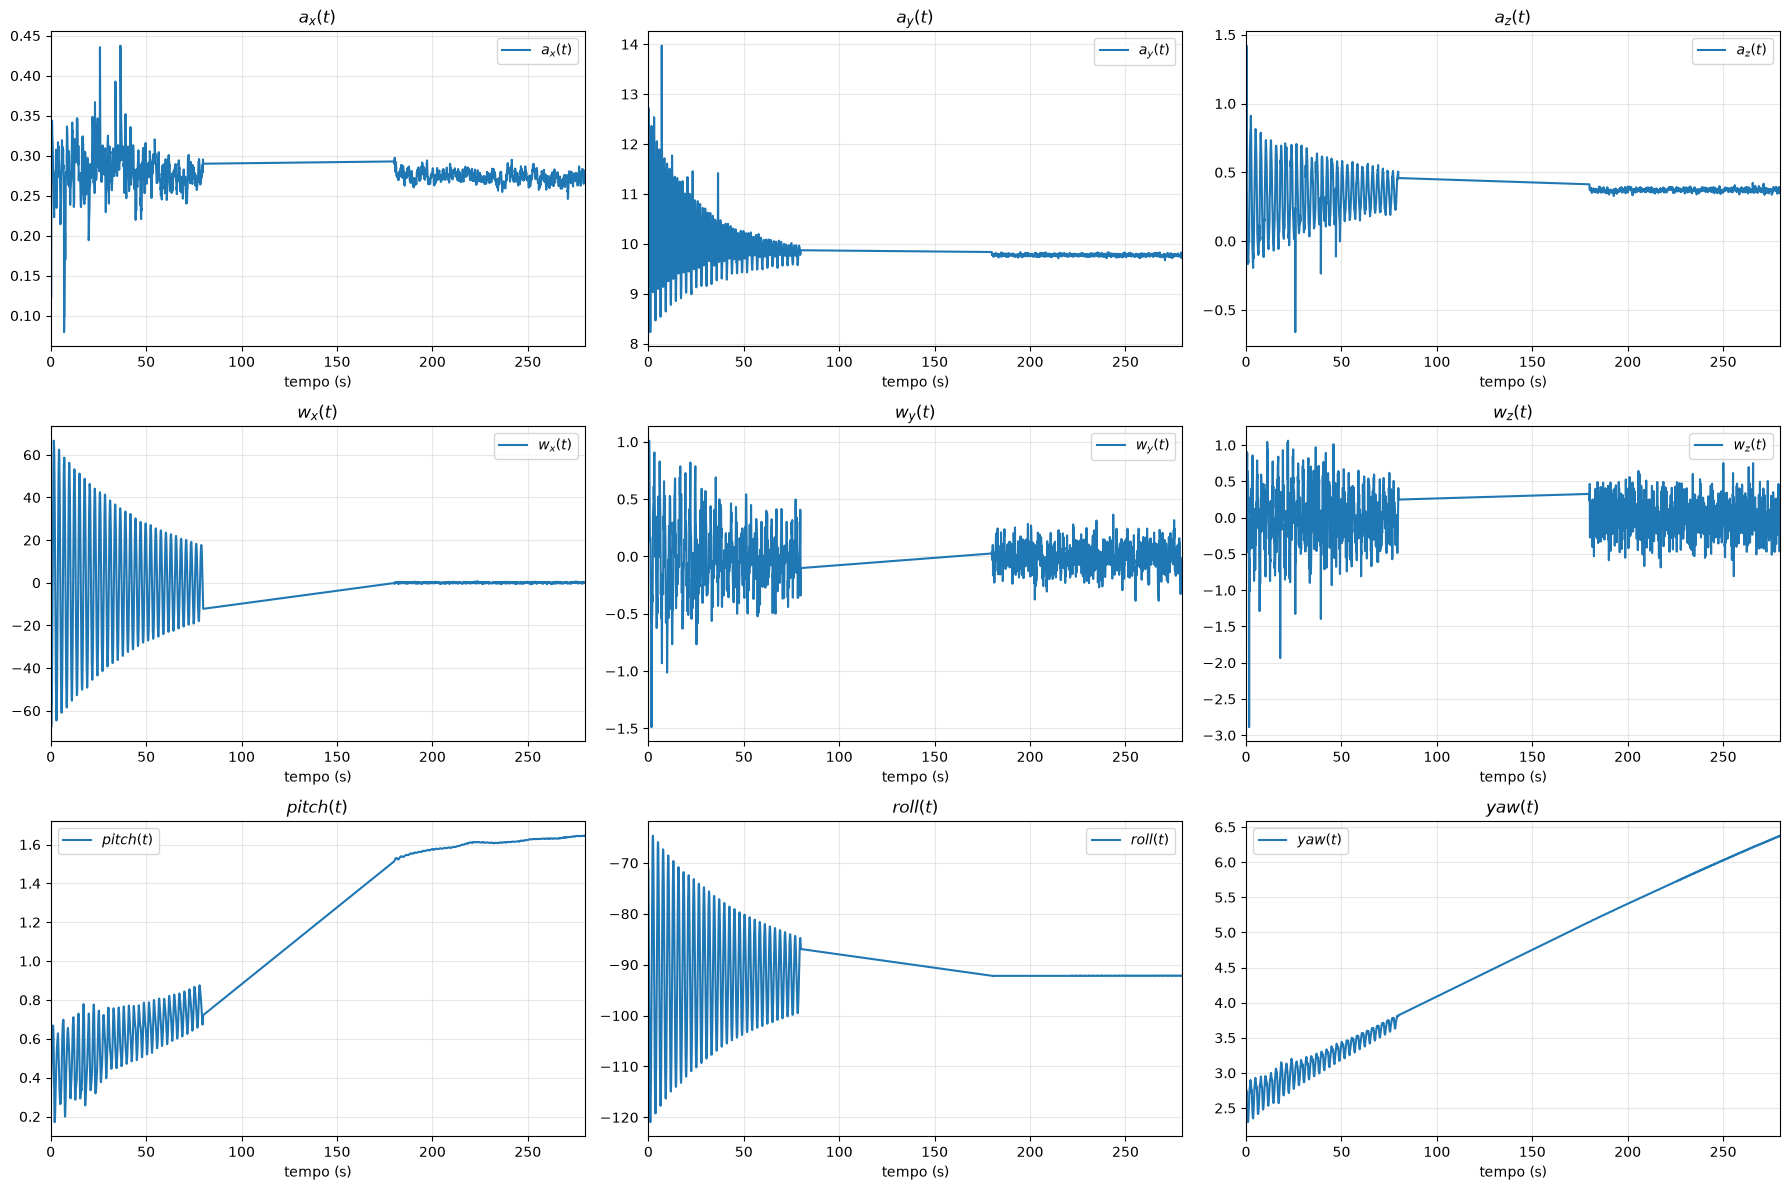

In [7]:
# GRADE DE SUBPLOTS RECORTADA POR FRAÇÃO DO TEMPO TOTAL
def compareAxis(time, data, limits=(0, 1), yLim=None):
    t_min, t_max = time.min(), time.max()
    delta = (t_max - t_min)

    start_time = t_min + (delta * limits[0])
    end_time   = t_min + (delta * limits[1])

    count   = len(data.keys())
    numCols = 3 if count >= 3 else count
    numRows = math.ceil(count / numCols)
    plt.figure(figsize=(6*numCols, 4*numRows))

    for i, (key, values) in enumerate(data.items()):
        mask = (time >= start_time) & (time <= end_time)

        plt.subplot(numRows, numCols, i+1)
        plt.plot(time[mask], values[mask], label=key)

        plt.xlim(start_time, end_time)
        if yLim: plt.ylim(yLim)
        plt.title(key); plt.xlabel('tempo (s)')
        plt.grid(alpha=0.3); plt.legend()

    plt.tight_layout()
    plt.show()


# PAINEL PADRÃO: GIROSCÓPIO, ACELERÔMETRO E ATITUDE DE REFERÊNCIA
def plotAll(df, limits=(0, 1)):
    compareAxis(df.time, {
        '$a_x(t)$': df.ax, '$a_y(t)$': df.ay, '$a_z(t)$': df.az,
        '$w_x(t)$': df.wx, '$w_y(t)$': df.wy, '$w_z(t)$': df.wz,
        '$pitch(t)$': df.pitch, '$roll(t)$': df.roll, '$yaw(t)$': df.yaw
    }, limits)


plotAll(df, limits=(0, 1))

# FILTRO DE KALMAN

Estado nominal: quaternion $q$ do corpo para a navegação (referencial com gravidade em $-z$, como o da
referência) e bias do giroscópio $b$. O erro é **multiplicativo**, $q_{real} = q \otimes \delta q(\delta\theta)$,
então quem entra na covariância é só $\delta x = [\,\delta\theta,\ \delta b\,] \in \mathbb{R}^6$: o quaternion
nunca é linearizado e não existe singularidade de Euler dentro do filtro.

**Propagação.** $q \leftarrow q \otimes \exp\big(\tfrac{1}{2}(\omega - b)\,\Delta t\big)$ com a exponencial
exata — a 10 Hz o passo chega a 7°, ângulo em que o seno já não pode ser linearizado. A dinâmica do erro é
$\dot{\delta\theta} = -[\omega\times]\delta\theta - \delta b$ e $\dot{\delta b} = 0$, cuja transição discreta é

$$\Phi = \begin{bmatrix} e^{-[\omega\times]\Delta t} & -\int_0^{\Delta t} e^{-[\omega\times]s}\,ds \\[2pt] 0 & I \end{bmatrix}$$

com $e^{-[\omega\times]\Delta t} = R(\omega\Delta t)^\top$ calculado do próprio incremento de quaternion. O ruído
discretizado (Farrell) carrega o termo cruzado, que é o que faz o bias convergir:
$Q_{\theta\theta} = \sigma_g^2 \Delta t + \sigma_b^2 \Delta t^3/3$, $Q_{\theta b} = -\sigma_b^2 \Delta t^2/2$,
$Q_{bb} = \sigma_b^2 \Delta t$.

**Correção do acelerômetro.** A medida é o versor $z = a/\lVert a \rVert$ e a predição $h = R^\top [0,0,-1]$.
Linearizando em torno do nominal, $z - h = [h\times]\,\delta\theta$, logo $H = [\,[h\times]\ \ 0\,]$. O posto de
$H$ é 2: a rotação em torno de $h$ — a proa — **não é observável sem magnetômetro**, e é por isso que $yaw_0$
entra como condição inicial e não como algo que o acelerômetro conserta.

**Braço de alavanca.** Num pêndulo o acelerômetro não mede só gravidade:

$$f = R^\top(-g) + \omega \times (\omega \times r) + \dot\omega \times r$$

Sem descontar os dois últimos termos o nivelamento erra ~9° durante o balanço; com $r$ estimado o erro cai para
~1,3°. Com $r = 0$ o modelo volta a ser o clássico, então nada se perde num sensor que não gira em torno de um
ponto externo.

**ZARU.** Nas janelas paradas a taxa verdadeira é zero: $z = \omega$, $h = b$, $H = [\,0\ \ I\,]$. Observa os
três eixos do bias, inclusive o vertical — o único jeito de segurar a deriva de proa sem magnetômetro.

**Joseph.** $P = (I-KH)P(I-KH)^\top + KRK^\top$ mantém $P$ simétrica e positiva definida ao longo de milhares
de correções, coisa que a forma $(I-KH)P$ não garante em ponto flutuante.

**Coning.** Dentro do passo o eixo de rotação também gira, e o incremento de duas amostras ganha o termo
$\tfrac{1}{12}(\omega_{k-1}\times\omega_k)\,\Delta t^2$: some quando o eixo não muda, como no balanço de um eixo só,
e é o que conserta o movimento cônico de um navio que joga e caturra ao mesmo tempo.

**Entrada.** Os sensores chegam filtrados e corrigidos nos eixos do navio pelo `2 - Correction`, em m/s² e graus/s:
a montagem deixou de ser parâmetro do filtro, e $g$ é o mesmo `gravity` do `info.json` que a correção usou.

**Repouso.** As janelas do ZARU saem do detector por norma, $\big||a| - g\big| < 0{,}2$ m/s² e $|\omega| < 1$ °/s, o mesmo
do firmware: a coluna `static` do ensaio só entra nas métricas, senão o notebook mediria um filtro que o MRU não roda.

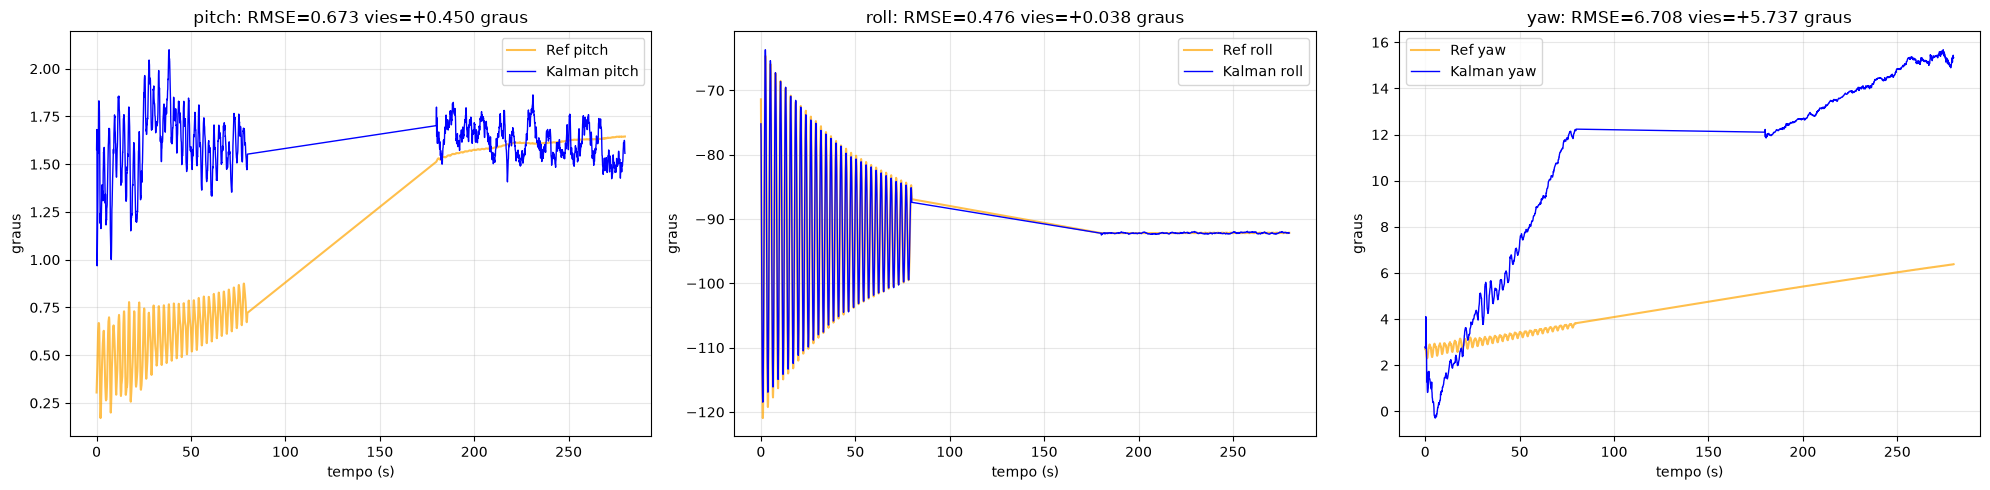

In [8]:
class KalmanFilter:
    NAV_GRAVITY = np.array([0.0, 0.0, -1.0])   # FORCA ESPECIFICA EM REPOUSO, NORMALIZADA
    TILT_P0     = 1.0                          # (rad^2) ATITUDE INICIAL DESCONHECIDA: DEIXA O ACCEL PUXAR
    BIAS_P0     = 1e-4                         # (rad/s)^2 BIAS INICIAL TIPICO DE UM MEMS JA COMPENSADO
    GAP_FACTOR  = 3.0                          # ACIMA DISSO O INTERVALO E BURACO DE AQUISICAO, NAO AMOSTRA
    STILL_ACCEL = 0.20                         # (m/s^2) TOLERANCIA DE |a|-g NO DETECTOR DE REPOUSO
    STILL_GYRO  = math.radians(1.0)            # (rad/s) TOLERANCIA DE |w| NO DETECTOR DE REPOUSO

    def __init__(self, df, xCols, yCols, params=None):
        self.df     = df.reset_index(drop=True).copy()
        self.xCols  = xCols
        self.yCols  = yCols
        self.params = params or {}

        p = self.params
        self.g          = p.get('g', GRAVITY)          # GRAVIDADE LOCAL (m/s^2), CENTRO DO GATE DO ACCEL
        self.gyroNoise  = 10 ** p.get('gyroNoise',  -6.0)   # log10 DA DENSIDADE DE RUIDO DO GIRO, (rad/s)^2/Hz
        self.biasNoise  = 10 ** p.get('biasNoise', -12.0)   # log10 DO RANDOM WALK DO BIAS, (rad/s^2)^2/Hz
        self.accelNoise = 10 ** p.get('accelNoise', -3.0)   # log10 DA VARIANCIA DO VERSOR DO ACELEROMETRO
        self.zuptNoise  = 10 ** p.get('zuptNoise',  -6.0)   # log10 DA VARIANCIA DO ZARU, (rad/s)^2
        self.accelGateK = 10 ** p.get('accelGateK',  1.0)   # log10 DO GANHO QUE INFLA R QUANDO |a| FOGE DE g
        self.lever      = np.array([p.get('leverX', 0.0), p.get('leverY', 0.0), p.get('leverZ', 0.0)])
        self.yaw0       = p.get('yaw0')                # PROA INICIAL (graus); None PEGA A DA REFERENCIA
        self.gyroPhase  = p.get('gyroPhase', 0.5)      # FASE DA TAXA INTEGRADA: 0 RETANGULAR, 0.5 TRAPEZOIDAL

    # PRODUTO DE HAMILTON ENTRE DOIS QUATERNIONS (w, x, y, z)
    def quatMul(self, q1, q2):
        w1, x1, y1, z1 = q1
        w2, x2, y2, z2 = q2
        return np.array([
            w1*w2 - x1*x2 - y1*y2 - z1*z2,
            w1*x2 + x1*w2 + y1*z2 - z1*y2,
            w1*y2 - x1*z2 + y1*w2 + z1*x2,
            w1*z2 + x1*y2 - y1*x2 + z1*w2,
        ])

    # EXPONENCIAL EXATA DO VETOR DE ROTACAO: A 10 Hz O PASSO CHEGA A 7 graus, ONDE O SENO JA NAO E LINEAR
    def quatFromRotVec(self, rotVec):
        angle = float(np.linalg.norm(rotVec))
        if angle < 1e-12:
            return np.array([1.0, *(rotVec / 2.0)])
        return np.array([math.cos(angle/2), *(rotVec / angle * math.sin(angle/2))])

    # MATRIZ DE ROTACAO CORPO -> NAVEGACAO (CONVENCAO DE HAMILTON, v_nav = R @ v_corpo)
    def quatToDCM(self, q):
        w, x, y, z = q
        return np.array([
            [1-2*(y*y+z*z), 2*(x*y-w*z),   2*(x*z+w*y)],
            [2*(x*y+w*z),   1-2*(x*x+z*z), 2*(y*z-w*x)],
            [2*(x*z-w*y),   2*(y*z+w*x),   1-2*(x*x+y*y)],
        ])

    # MATRIZ ANTISSIMETRICA (v x)
    def skew(self, v):
        return np.array([
            [0, -v[2], v[1]],
            [v[2], 0, -v[0]],
            [-v[1], v[0], 0],
        ])

    # NIVELAMENTO PELO ACELEROMETRO: u = R.T @ [0,0,-1] DA rolagem E arfagem; A PROA VEM DE FORA
    def initQuat(self, u, yaw):
        roll  = math.atan2(-u[1], -u[2])
        pitch = math.atan2(u[0], math.hypot(u[1], u[2]))
        x, y, z, w = Rotation.from_euler('xyz', [roll, pitch, math.radians(yaw)]).as_quat()
        return np.array([w, x, y, z])

    # PROPAGA ATITUDE E BIAS; dtQ E O TEMPO REAL DECORRIDO, dt O INTEGRADO (LIMITADO EM BURACOS), cone O TERMO DE DOIS INSTANTES
    def predict(self, q, b, P, gyro, dt, dtQ, cone):
        w  = gyro - b
        dq = self.quatFromRotVec(w * dt + cone)
        q  = self.quatMul(q, dq)
        q /= np.linalg.norm(q)

        S = self.skew(w)
        F = np.eye(6)
        F[:3, :3] = self.quatToDCM(dq).T                                  # exp(-[w x] dt) EXATO
        F[:3, 3:] = -(np.eye(3)*dt - S*dt**2/2 + S@S*dt**3/6)             # -integral de exp(-[w x] s) ds

        sg, sb, I = self.gyroNoise, self.biasNoise, np.eye(3)
        Q = np.zeros((6, 6))
        Q[:3, :3] = I * (sg*dtQ + sb*dtQ**3/3)
        Q[:3, 3:] = Q[3:, :3] = I * (-sb*dtQ**2/2)            # o termo cruzado e o que faz o bias convergir
        Q[3:, 3:] = I * (sb*dtQ)
        return q, b, F @ P @ F.T + Q

    # CORRECAO MULTIPLICATIVA (MEKF): injeta o erro linearizado [dTheta, dBias] no estado nominal
    def correct(self, q, b, P, H, innovation, R):
        K  = P @ H.T @ np.linalg.inv(H @ P @ H.T + R)
        dx = K @ innovation

        q  = self.quatMul(q, self.quatFromRotVec(dx[:3]))
        q /= np.linalg.norm(q)

        A = np.eye(6) - K @ H
        P = A @ P @ A.T + K @ R @ K.T                         # forma de Joseph, robusta a erro numerico
        return q, b + dx[3:], (P + P.T) / 2

    # JANELAS PARADAS PELO MESMO DETECTOR DO FIRMWARE: A COLUNA static DO ENSAIO SO SERVE PARA METRICA
    def ready(self, accel, gyro):
        quiet = np.abs(np.linalg.norm(accel, axis=1) - self.g) < self.STILL_ACCEL
        return quiet & (np.linalg.norm(gyro, axis=1) < self.STILL_GYRO)

    # RODA O FILTRO AMOSTRA A AMOSTRA E GUARDA QUATERNIONS, ANGULOS E BIAS
    def update(self):
        ax, ay, az, wx, wy, wz = self.xCols
        accel = self.df[[ax, ay, az]].to_numpy()
        gyro  = np.radians(self.df[[wx, wy, wz]].to_numpy())

        time  = self.df.time.to_numpy()
        dtNom = float(np.median(np.diff(time))) if len(time) > 1 else 1.0
        dtQ = np.diff(time, prepend=time[0])               # a primeira so inicializa: nada decorreu antes
        gap = dtQ > self.GAP_FACTOR * dtNom
        dt  = np.minimum(dtQ, self.GAP_FACTOR * dtNom)

        alpha      = np.zeros_like(gyro)
        alpha[1:]  = np.diff(gyro, axis=0) / dtQ[1:, None]
        alpha[gap] = 0.0
        alpha[0]   = alpha[1] if len(alpha) > 1 else 0.0    # sem anterior ela entraria sem o termo tangencial
        rate       = gyro.copy()                            # a marca do giro nao cai no meio do passo
        rate[1:]   = gyro[1:] - self.gyroPhase * (gyro[1:] - gyro[:-1])
        rate[gap]  = gyro[gap]
        cone       = np.zeros_like(gyro)
        cone[1:]   = np.cross(gyro[:-1], gyro[1:]) * dt[1:, None]**2 / 12    # coning: some quando o eixo nao muda
        cone[gap]  = 0.0
        lever      = np.array([(self.skew(w) @ self.skew(w) + self.skew(a)) @ self.lever
                                 for w, a in zip(gyro, alpha)])
        accel  = accel - lever                          # tira a aceleracao do braco de alavanca
        norm   = np.linalg.norm(accel, axis=1)
        gate   = 1 + self.accelGateK * ((norm - self.g) / self.g) ** 2
        static = self.ready(accel, gyro)

        yaw = self.yaw0 if self.yaw0 is not None else float(self.df[self.yCols[2]].iloc[0])
        up  = accel[0] / norm[0] if norm[0] > 1e-6 else self.NAV_GRAVITY   # sem leitura util, comeca nivelado
        q   = self.initQuat(up, yaw)
        b   = np.zeros(3)
        P   = np.diag([self.TILT_P0]*3 + [self.BIAS_P0]*3)

        quats = np.zeros((len(self.df), 4))
        for i in range(len(self.df)):
            q, b, P = self.predict(q, b, P, rate[i], dt[i], dtQ[i], cone[i])

            if gap[i]:
                P[:3, :3] = np.eye(3) * self.TILT_P0   # buraco: so o accel reancora a atitude

            if norm[i] > 1e-6:
                h = -self.quatToDCM(q)[2]              # R.T @ [0,0,-1] e menos a 3a linha
                H = np.zeros((3, 6))
                H[:, :3] = self.skew(h)
                q, b, P  = self.correct(q, b, P, H, accel[i]/norm[i] - h, self.accelNoise * gate[i] * np.eye(3))

            if static[i]:
                H = np.zeros((3, 6))
                H[:, 3:] = np.eye(3)
                q, b, P  = self.correct(q, b, P, H, gyro[i] - b, self.zuptNoise * np.eye(3))

            quats[i] = q

        euler = Rotation.from_quat(quats[:, [1, 2, 3, 0]]).as_euler('xyz', degrees=True)
        euler = np.degrees(np.unwrap(np.radians(euler), axis=0))   # continuidade em +-180, sem saltos

        self.quats  = quats
        self.bias   = np.degrees(b)
        self.euler  = euler
        self.result = self.df.copy()

        for k, name in enumerate(['roll', 'pitch', 'yaw']):
            self.result[f'kalman_{name}'] = euler[:, k]

    # DIFERENCA ANGULAR NO RAMO CURTO: SEM ISSO UM SALTO DE 360 VIRA ERRO DE 360
    def error(self, name, refCol):
        return (self.result[f'kalman_{name}'].to_numpy() - self.result[refCol].to_numpy() + 180) % 360 - 180

    def get(self):
        data = {}
        for name, refCol in zip(['pitch', 'roll', 'yaw'], self.yCols):
            err  = self.error(name, refCol)
            corr = np.corrcoef(self.result[f'kalman_{name}'], self.result[refCol])[0, 1]
            rmse = float(np.sqrt(np.mean(err**2)))
            data[refCol] = {'rmse': rmse, 'bias': float(np.mean(err)), 'corr': float(corr)}
        return data

    def info(self):
        return {'bias': self.bias.round(4).tolist(), **{k: round(v['rmse'], 4) for k, v in self.get().items()}}

    def plot(self, xlim=None, save=None):
        plt.figure(figsize=(20, 5))

        for i, (name, refCol) in enumerate(zip(['pitch', 'roll', 'yaw'], self.yCols)):
            err = self.error(name, refCol)
            plt.subplot(1, 3, i + 1)
            plt.plot(self.result.time, self.result[refCol], label=f'Ref {refCol}', color='orange', alpha=.7)
            plt.plot(self.result.time, self.result[f'kalman_{name}'], label=f'Kalman {name}', color='blue', linewidth=1)
            plt.title(f'{refCol}: RMSE={np.sqrt(np.mean(err**2)):.3f} vies={np.mean(err):+.3f} graus')
            plt.xlabel('tempo (s)'); plt.ylabel('graus'); plt.grid(alpha=.3); plt.legend()
            if xlim is not None: plt.xlim(xlim)

        plt.tight_layout()
        if save: plt.savefig(save, dpi=110, bbox_inches='tight')
        plt.show()


kf = KalmanFilter(df, xCols=xCols, yCols=yCols, params={
    'gyroNoise' :    -3.243099,
    'biasNoise' :   -14.169008,
    'accelNoise':    -1.510183,
    'zuptNoise' :     0.803745,
    'accelGateK':     3.869210,
    'leverX'    :     1.871451,
    'leverY'    :    -1.735827,
    'leverZ'    :     0.151919,
    'gyroPhase' :     0.480341,
})
kf.update()
kf.plot()

# OTIMIZAÇÃO DOS PARÂMETROS

As quatro covariâncias e o ganho do gate entram em **log10**: elas variam por décadas, e a CMA-ES usa um passo
inicial único, $\sigma_0 = 0{,}3\,\overline{(sup - inf)}$, para todas as dimensões — com limites lineares de
$10^{-12}$ a $10^{-1}$ ela nunca visitaria a região certa. Em log10 todas as caixas ficam com largura
comparável (10 a 30), que é a condição para o passo isotrópico inicial fazer sentido.

`g` fica de fora da busca: ele só centra o gate e é a gravidade local do `info.json`, a mesma que
a correção usou para escalar o acelerômetro. Gastar uma dimensão de largura 0,2 numa caixa onde as outras têm largura 10 estragaria o
$\sigma_0$ de todo mundo.

genetic:   0%|          | 0/3000 [00:00<?, ?ev/s]

genetic:   0%|          | 15/3000 [00:00<02:41, 18.50ev/s]

genetic:   1%|          | 30/3000 [00:01<01:49, 27.01ev/s, best=1.12694, pop=15]

genetic:   2%|▏         | 45/3000 [00:01<01:32, 31.85ev/s, best=1.12694, pop=15]

genetic:   2%|▏         | 60/3000 [00:01<01:25, 34.25ev/s, best=1.12694, pop=15]

...

genetic:  98%|█████████▊| 2955/3000 [01:18<00:01, 37.50ev/s, best=0.90972, pop=15]

genetic:  99%|█████████▉| 2970/3000 [01:19<00:00, 37.08ev/s, best=0.90972, pop=15]

genetic: 100%|█████████▉| 2985/3000 [01:19<00:00, 37.11ev/s, best=0.90972, pop=15]

genetic: 100%|██████████| 2985/2985 [01:19<00:00, 37.58ev/s, best=0.909719, pop=15]


soma de RMSE: 0.9097 graus


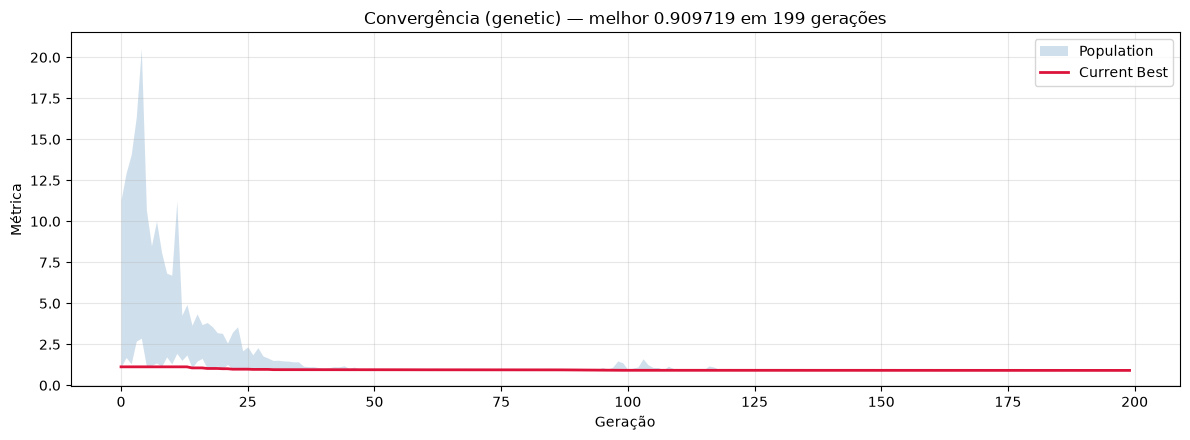

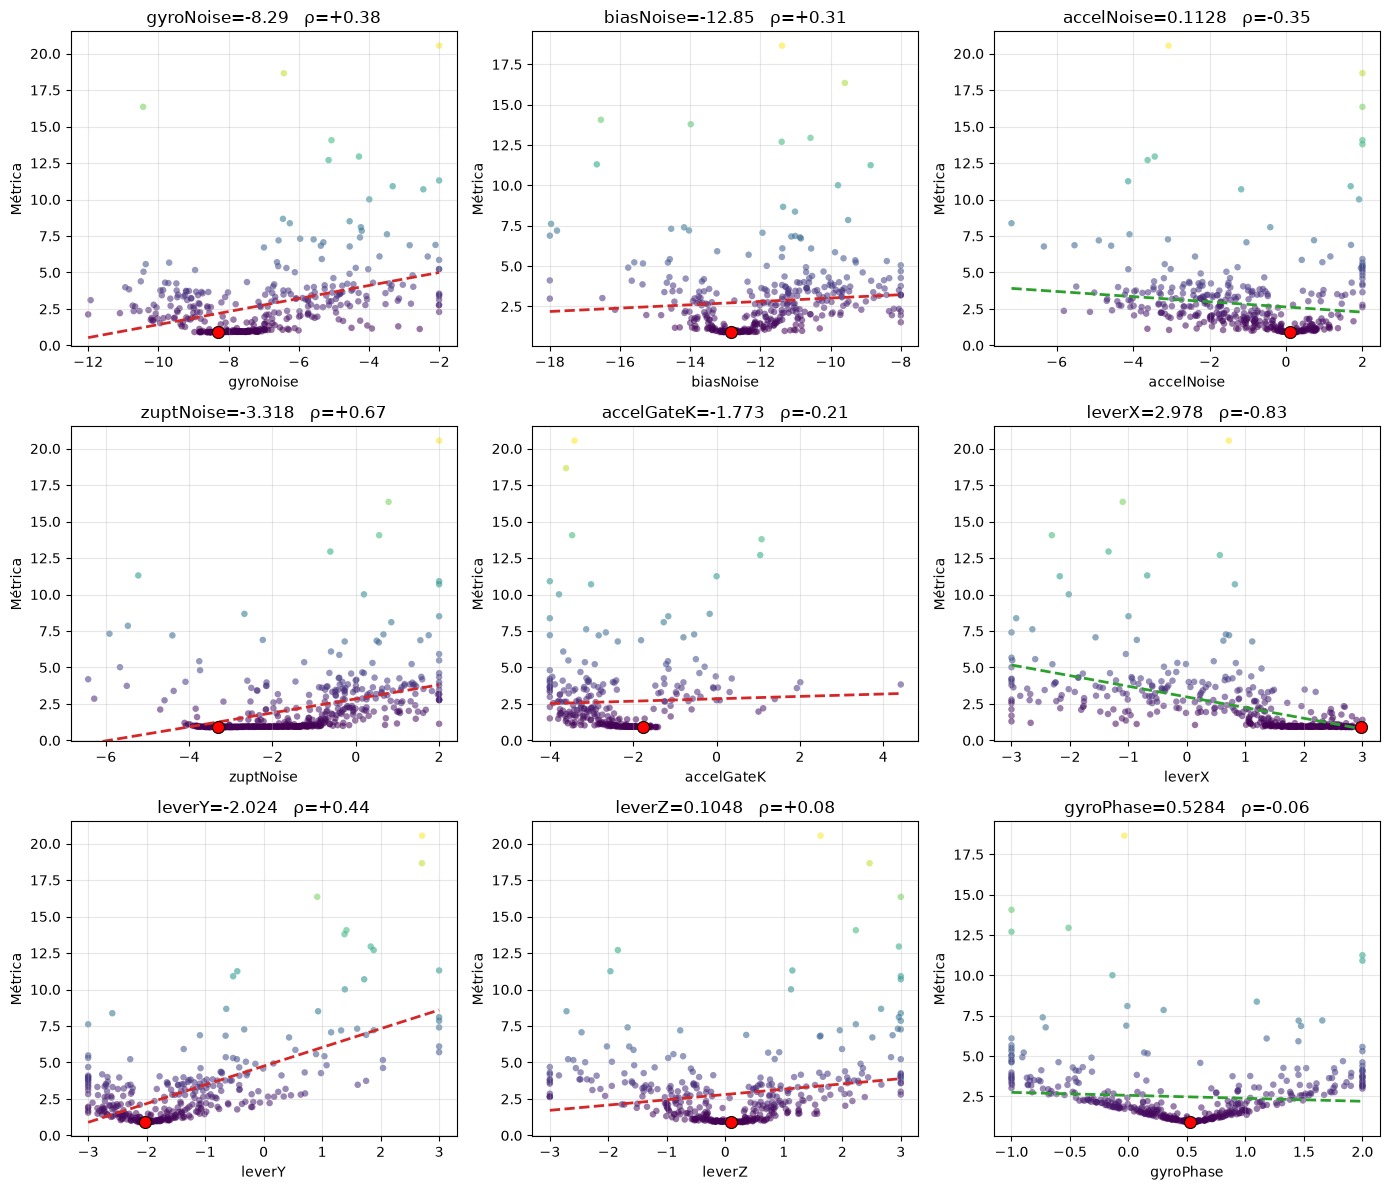

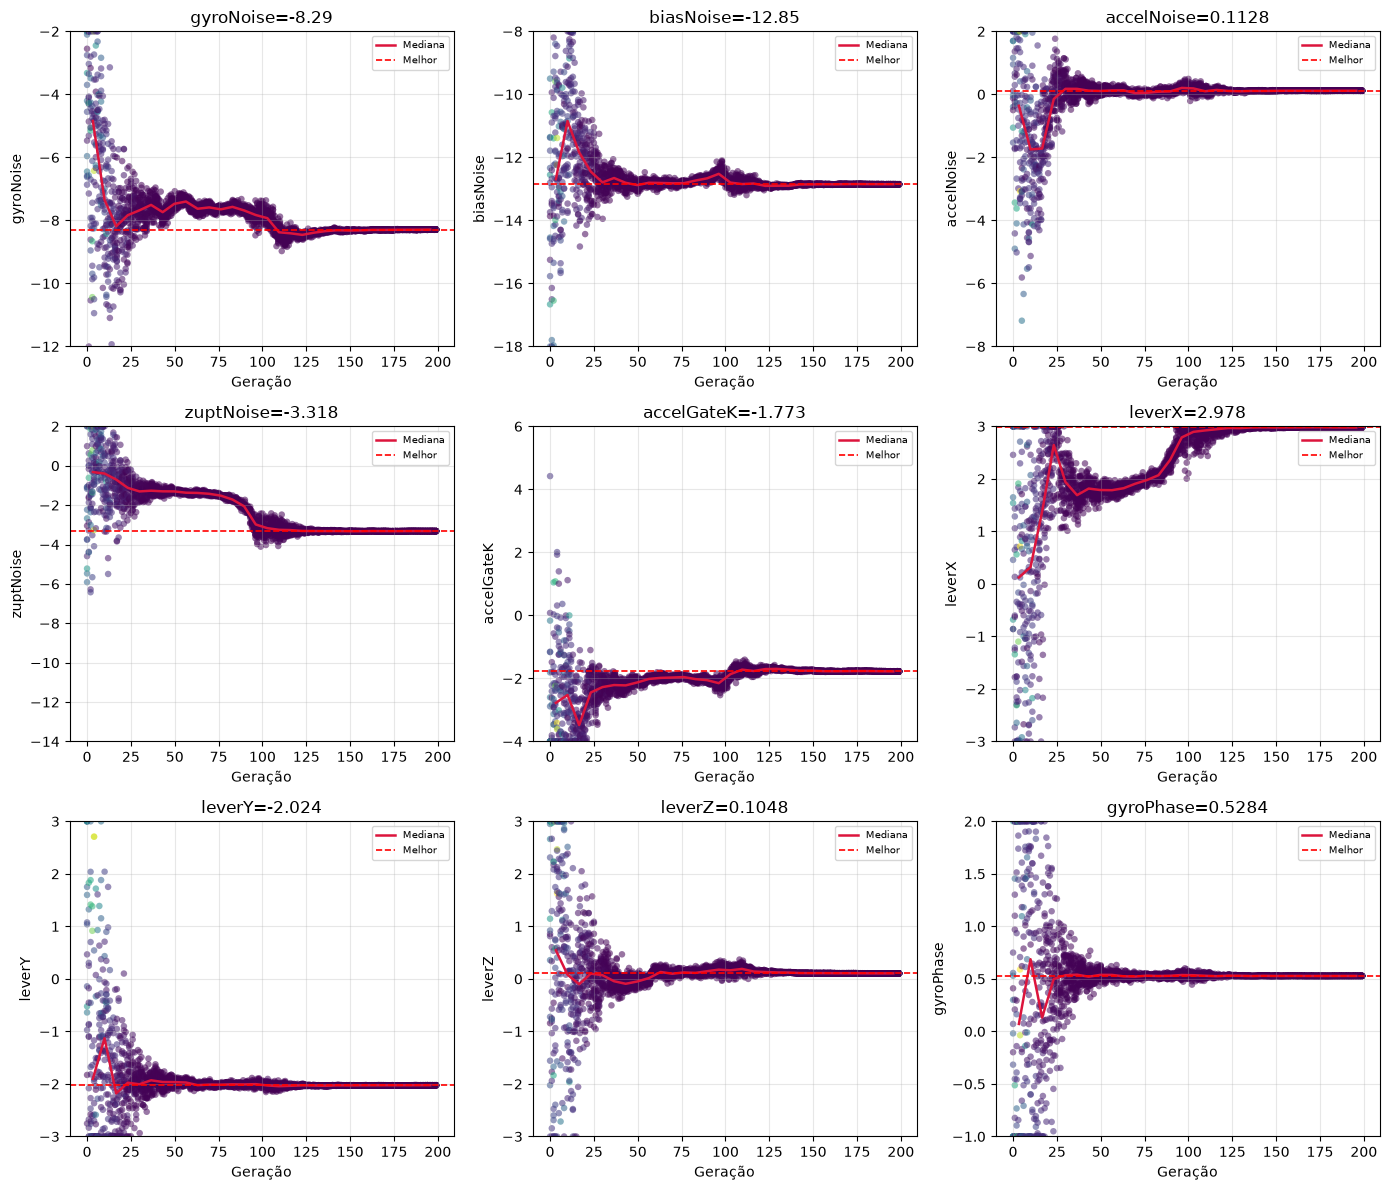

In [9]:
from Nature.index import NatureSelector

def objective(params):
    kf = KalmanFilter(df, xCols=xCols, yCols=yCols, params=params)
    kf.update()
    result = kf.get()
    return result['pitch']['rmse'] + result['roll']['rmse']


problem = {
    'objective': objective, 'maximize': False, 'seed': 42, 'verbose': True,
    'variables': {
        'gyroNoise':  {'bounds': (-12.0,  -2.0)},   # log10 (rad/s)^2/Hz   ARW do giro: 1e-12 a 1e-2
        'biasNoise':  {'bounds': (-18.0,  -8.0)},   # log10 (rad/s^2)^2/Hz random walk do bias
        'accelNoise': {'bounds': ( -8.0,   2.0)},   # log10 variancia do versor do acelerometro
        'zuptNoise':  {'bounds': (-14.0,   2.0)},   # log10 (rad/s)^2 do ZARU; o topo desliga a correcao
        'accelGateK': {'bounds': ( -4.0,   6.0)},   # log10 do ganho que infla R quando |a| foge de g
        'leverX':     {'bounds': ( -3.0,   3.0)},   # metros, do centro de rotacao ate o sensor, no corpo
        'leverY':     {'bounds': ( -3.0,   3.0)},
        'leverZ':     {'bounds': ( -3.0,   3.0)},
        'gyroPhase':  {'bounds': ( -1.0,   2.0)},   # fase da taxa integrada: 0 retangular, 0.5 trapezoidal
    }
}
  
SEARCH = {'population': 15, 'generations': 200, 'workers': 8, 'backend': 'process'}
RUNS   = 1

model = NatureSelector('genetic', {**problem, **SEARCH}, n_gaussian=RUNS)
best, score = model.update()

print(f'soma de RMSE: {score:.4f} graus')
model.plotMetrics()
model.plotVariables('range')
model.plotVariables('temporal')

In [10]:
model.getBest()

{'algorithm': 'genetic',
 'f': 0.9097186795465787,
 'runs': 1,
 'stopped': 199,
 'variables': {'gyroNoise': -8.28950034192057,
  'biasNoise': -12.850986893646986,
  'accelNoise': 0.11279023869808216,
  'zuptNoise': -3.3177947807165333,
  'accelGateK': -1.7730422340097656,
  'leverX': 2.977951906768182,
  'leverY': -2.02417821394319,
  'leverZ': 0.10480772748892238,
  'gyroPhase': 0.5284163997757426}}

# VISUALIZAÇÃO FINAL

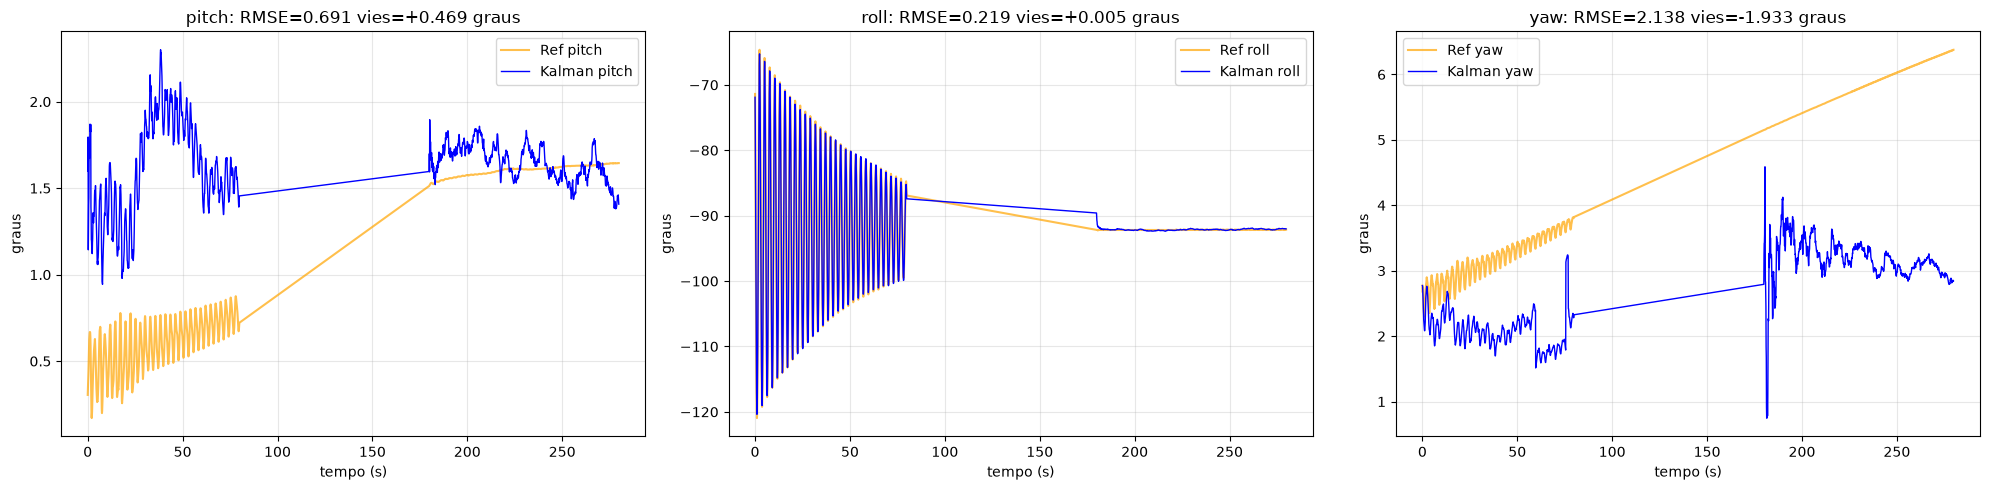

In [11]:
kf = KalmanFilter(df, xCols=xCols, yCols=yCols, params=best)
kf.update()
kf.plot()

# BACKUP DOS PARÂMETROS

In [12]:
os.makedirs('Backup', exist_ok=True)
saved  = [name for name in os.listdir('Backup') if name.startswith('model_')]    # O target.csv TEMPORÁRIO TAMBÉM MORA NO Backup
index  = len(saved) + 1

output = f'Backup/model_{index}'
os.makedirs(output, exist_ok=True)

results = {
    **model.getBest(),
    'search':  {**SEARCH, 'seed': problem['seed'], 'bounds': {k: v['bounds'] for k, v in problem['variables'].items()}},
    'metrics': kf.get(),
    'bias':    kf.bias.round(6).tolist(),
    'dataset': {'path': SOURCE, 'samples': len(df), 'dt': float(dt), 'xCols': xCols, 'yCols': yCols}
}

pd.Series(results).to_json(f'{output}/info.json', indent=4)
print(output)
results

Backup/model_4


{'algorithm': 'genetic',
 'f': 0.9097186795465787,
 'runs': 1,
 'stopped': 199,
 'variables': {'gyroNoise': -8.28950034192057,
  'biasNoise': -12.850986893646986,
  'accelNoise': 0.11279023869808216,
  'zuptNoise': -3.3177947807165333,
  'accelGateK': -1.7730422340097656,
  'leverX': 2.977951906768182,
  'leverY': -2.02417821394319,
  'leverZ': 0.10480772748892238,
  'gyroPhase': 0.5284163997757426},
 'search': {'population': 15,
  'generations': 200,
  'workers': 8,
  'backend': 'process',
  'seed': 42,
  'bounds': {'gyroNoise': (-12.0, -2.0),
   'biasNoise': (-18.0, -8.0),
   'accelNoise': (-8.0, 2.0),
   'zuptNoise': (-14.0, 2.0),
   'accelGateK': (-4.0, 6.0),
   'leverX': (-3.0, 3.0),
   'leverY': (-3.0, 3.0),
   'leverZ': (-3.0, 3.0),
   'gyroPhase': (-1.0, 2.0)}},
 'metrics': {'pitch': {'rmse': 0.6908653659667036,
   'bias': 0.46871377202625014,
   'corr': 0.18835128352199998},
  'roll': {'rmse': 0.21885331357987514,
   'bias': 0.005055035359059193,
   'corr': 0.9996526694164989}

# SALVANDO A ATITUDE
- Ângulos do filtro ao lado dos da referência (`_ref`): `attitude.csv` é a entrada do `4 - Heave` e do `Analysis.ipynb`

In [13]:
attitude = kf.result[['time', 'static']].copy()

for name in yCols:
    attitude[name]          = kf.result[f'kalman_{name}']
    attitude[f'{name}_ref'] = kf.result[name]

record = {
    'strategy': 'kalman_fusion',
    'backup':   f'3 - Attitude/KalmanFusion/{output}',
    'targets':  yCols,
    'metrics':  kf.get()
}

os.makedirs(RESULTS, exist_ok=True)
attitude.to_csv(f'{RESULTS}/attitude.csv', index=None)
pd.Series(record).to_json(f'{RESULTS}/attitude.json', indent=4)
print(f'{RESULTS}/attitude.csv')
attitude

../../Dataset/test1/results/attitude.csv


,time,static,pitch,pitch_ref,roll,roll_ref,yaw,yaw_ref
0,0.0,False,1.599845,0.304871,-71.897500,-71.390541,2.771970,2.771970
1,0.1,False,1.684539,0.337243,-75.608591,-76.661753,2.768606,2.723841
2,0.2,False,1.795699,0.366750,-81.710402,-82.677810,2.698839,2.667691
3,0.3,False,1.143599,0.387721,-89.879315,-89.209529,2.611133,2.743322
4,0.4,False,1.321783,0.442381,-96.584411,-95.913135,2.525740,2.624720
...,...,...,...,...,...,...,...,...
1795,279.4,True,1.450643,1.644962,-91.997023,-92.131613,2.838353,6.371291
1796,279.5,True,1.460980,1.645535,-92.004264,-92.131613,2.839472,6.371291
1797,279.6,True,1.441916,1.644962,-92.013951,-92.131613,2.853583,6.371291
1798,279.7,True,1.415758,1.645535,-92.021818,-92.131613,2.847150,6.377020


# EXPORTANDO PARA O FIRMWARE
- Vão os parâmetros do filtro que acabou de rodar, já em unidade física: o `.h` não repete o log10 da busca
- O `config.h` do `attitude` diz qual modelo o firmware compila; quem exportar por último é quem roda, do mesmo jeito que o `attitude.csv` do teste

In [14]:
FIRMWARE = '../../../Hardware/Embedded/Main/objects/processing/attitude'
STAMP    = f'{datetime.date.today():%d/%m/%Y}'

lever   = ', '.join(f'{value:.8f}f' for value in kf.lever)
heading = 'NAN' if kf.yaw0 is None else f'{kf.yaw0:.6f}f'

header = f'''#ifndef KALMAN_CONFIG_H
#define KALMAN_CONFIG_H

// GERADO POR Calibration/3 - Attitude/KalmanFusion/1 - Model.ipynb EM {STAMP}
#define KALMAN_NAME        "kalman_fusion"
#define KALMAN_GRAVITY     {kf.g:.6f}f
#define KALMAN_GYRO_NOISE  {kf.gyroNoise:.8e}f     // (rad/s)^2/Hz do ARW do giro
#define KALMAN_BIAS_NOISE  {kf.biasNoise:.8e}f     // (rad/s^2)^2/Hz do random walk do bias
#define KALMAN_ACCEL_NOISE {kf.accelNoise:.8e}f    // variancia do versor do acelerometro
#define KALMAN_ZUPT_NOISE  {kf.zuptNoise:.8e}f     // (rad/s)^2 do ZARU
#define KALMAN_ACCEL_GATE  {kf.accelGateK:.8e}f    // ganho que infla R quando |a| foge de g
#define KALMAN_GYRO_PHASE  {kf.gyroPhase:.6f}f     // fase da taxa integrada: 0 retangular, 0.5 trapezoidal
#define KALMAN_HEADING     {heading}    // proa inicial em graus; NAN pega a do sensor

static const float KALMAN_LEVER[3] = {{{lever}}};    // metros, do centro de rotacao ate o sensor, no corpo

#endif
'''

select = f'''#ifndef ATTITUDE_CONFIG_H
#define ATTITUDE_CONFIG_H
#include "kalman/index.h"

// GERADO POR Calibration/3 - Attitude/KalmanFusion/1 - Model.ipynb EM {STAMP}
using AttitudeModel = KalmanModel;

#endif
'''

open(f'{FIRMWARE}/kalman/config.h', 'w').write(header)
open(f'{FIRMWARE}/config.h', 'w').write(select)

print(f'{FIRMWARE}/kalman/config.h')
print(header)

../../../Hardware/Embedded/Main/objects/processing/attitude/kalman/config.h
#ifndef KALMAN_CONFIG_H
#define KALMAN_CONFIG_H

// GERADO POR Calibration/3 - Attitude/KalmanFusion/1 - Model.ipynb EM 15/10/2026
#define KALMAN_NAME        "kalman_fusion"
#define KALMAN_GRAVITY     9.785000f
#define KALMAN_GYRO_NOISE  5.13451773e-09f     // (rad/s)^2/Hz do ARW do giro
#define KALMAN_BIAS_NOISE  1.40933133e-13f     // (rad/s^2)^2/Hz do random walk do bias
#define KALMAN_ACCEL_NOISE 1.29655289e+00f    // variancia do versor do acelerometro
#define KALMAN_ZUPT_NOISE  4.81066615e-04f     // (rad/s)^2 do ZARU
#define KALMAN_ACCEL_GATE  1.68638902e-02f    // ganho que infla R quando |a| foge de g
#define KALMAN_GYRO_PHASE  0.528416f     // fase da taxa integrada: 0 retangular, 0.5 trapezoidal
#define KALMAN_HEADING     NAN    // proa inicial em graus; NAN pega a do sensor

static const float KALMAN_LEVER[3] = {2.97795191f, -2.02417821f, 0.10480773f};    // metros, do centro de rotacao ate o sensor